# Hands-on 25: Perbandingan 3 Model dengan Metrik Evaluasi dan Visualisasi Kurva

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 8.

Klasifikasi status: Logistic Regression vs Random Forest vs Gradient Boosting
(accuracy, precision/recall/F1 weighted, kurva ROC one-vs-rest).
Variasi regresi: Linear vs Random Forest vs Gradient Boosting (MAE/RMSE).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Perbandingan 3 Model Klasifikasi

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/compare_three_models_status.py"], capture_output=True, text=True)
print(r.stdout)

=== HASIL PERBANDINGAN MODEL ===
                model  accuracy  ...  recall_weighted  f1_weighted
0  LogisticRegression  0.990741  ...         0.990741     0.990208
2    GradientBoosting  0.984568  ...         0.984568     0.984295
1        RandomForest  0.984568  ...         0.984568     0.983680

[3 rows x 5 columns]

Disimpan ke: outputs/reports/model_comparison_status.csv



## 2. Visualisasi Metrik dan Kurva ROC

Figure(1000x500)
Figure(1000x500)



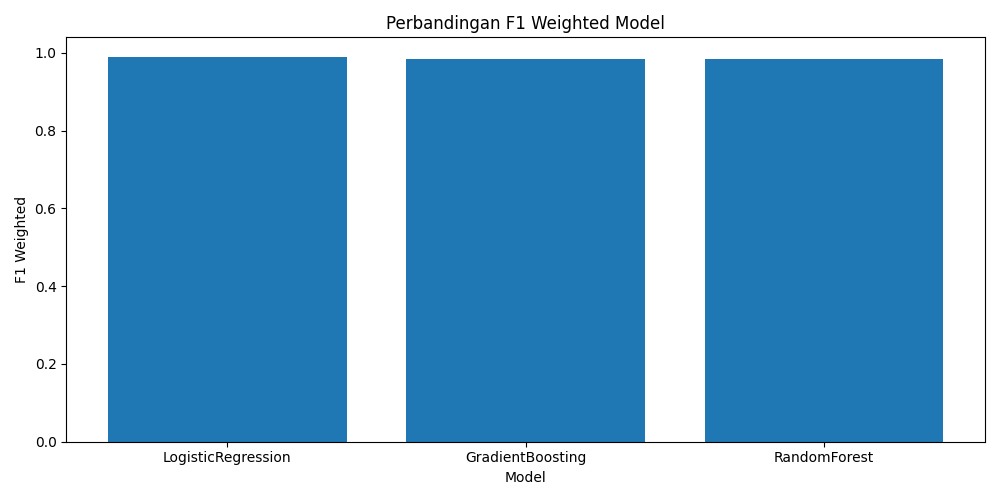

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_model_comparison.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/compare_f1_models.png")

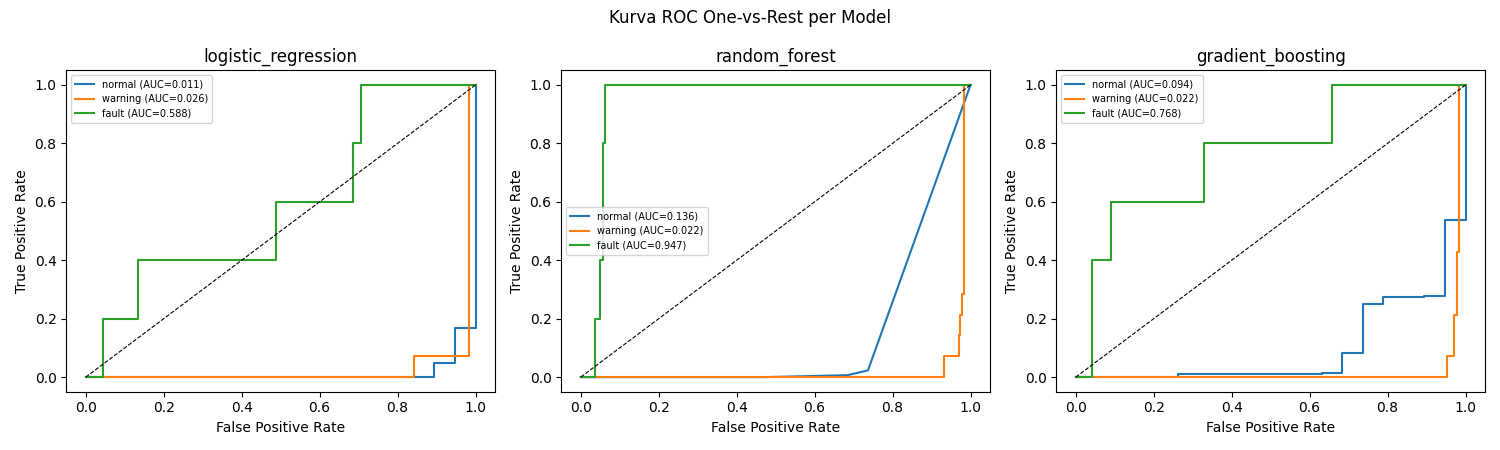

In [4]:
Image("outputs/figures/compare_roc_curves.png")

## 3. Variasi: Perbandingan 3 Regresor Energi

In [5]:
r = subprocess.run([sys.executable, "scripts/compare_three_regressors.py"], capture_output=True, text=True)
print(r.stdout)

                       model        mae       rmse
2  GradientBoostingRegressor  18.766005  26.923245
0           LinearRegression  17.304487  27.200182
1      RandomForestRegressor  18.777902  27.354285
Disimpan ke: outputs/reports/model_comparison_regression.csv



## Penutup

Klasifikasi: Logistic Regression unggul tipis (F1 weighted sekitar 0.987) karena kelas
terpisah hampir linear; ROC menunjukkan AUC tinggi untuk ketiga model. Regresi: Linear
Regression justru terbaik di test (MAE sekitar 17.3) karena pola energi sangat periodik.
Laporan tersimpan di `outputs/reports/model_comparison_*.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 22 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 5. Variasi perbandingan untuk regresi

Jika Anda ingin membandingkan 3 model regresi, gunakan:
- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor
Buat file scripts/compare_three_regressors.py:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,
GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
DATA_DIR = Path("data/processed/regression_energy")
OUTPUT_DIR = Path("outputs/reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()
models = {
"LinearRegression": LinearRegression(),
"RandomForestRegressor": RandomForestRegressor(
n_estimators=200, max_depth=10, random_state=42, n_jobs=-1
),
"GradientBoostingRegressor":
GradientBoostingRegressor(random_state=42)
}
results = []
for name, model in models.items():
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
results.append({
"model": name,
"mae": mae,
"rmse": rmse
})
results_df = pd.DataFrame(results).sort_values("rmse")
print(results_df)
results_df.to_csv(OUTPUT_DIR / "model_comparison_regression.csv",
index=False)

print("Disimpan ke:", OUTPUT_DIR / "model_comparison_regression.csv")

### 8. Langkah kerja yang harus dilakukan pembaca

Tahap 1
Siapkan dataset regresi dan klasifikasi yang sudah time-aware.
Tahap 2
Latih model baseline sederhana:
- Linear Regression
- Logistic Regression
Tahap 3
Latih model ensemble:
- Random Forest Regressor
- Random Forest Classifier
- Gradient Boosting

Tahap 4
Hitung metrik:
- regresi → MAE, RMSE
- klasifikasi → accuracy, precision, recall, F1, confusion matrix
Tahap 5
Visualisasikan:
- aktual vs prediksi untuk regresi
- bar chart perbandingan model untuk klasifikasi/regresi
Tahap 6
Tafsirkan hasil bukan hanya dari skor tertinggi, tetapi juga dari:

kestabilan,
kemudahan implementasi,
kemudahan penjelasan,
dan kebutuhan lapangan.